# Dressed States Simulations

## Imports and Definitions

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from glob import glob
from scipy.constants import physical_constants
from scipy.optimize import curve_fit
from multiprocessing import Pool
from functools import partial

import simFunctions as sim

In [2]:
# just the normal pi = 3.1415
pi = np.pi

# gyromagnetic ratio of the proton in [rad/s/T]
gamma_p = physical_constants['proton gyromag. ratio'][0]

## Analyze

### Spectra

resonance frequency: 	(996.8 ± 0.3) Hz
resonance width: 	(29.3 ± 0.3) Hz


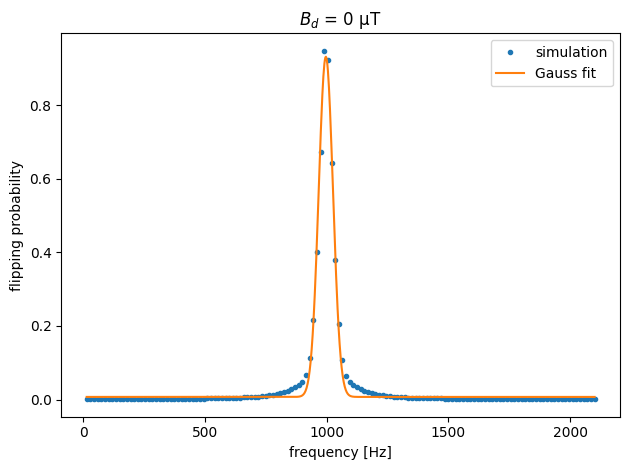

In [3]:
i = 0

# load the simulated data
file = f'sim/dressedStates_{i:02d}.npz'
Bd = np.load(file)['Bd']
F_SF = np.load(file)['F_SF']
Amp = np.load(file)['Amp']

popt = (1000, 1, 30, 0)
popt, pcov = curve_fit(sim.gaussFct, F_SF, Amp, p0=popt)
perr = np.sqrt(np.diag(pcov))
print(f'resonance frequency: \t({popt[0]:.1f} ± {perr[0]:.1f}) Hz')
print(f'resonance width: \t({popt[2]:.1f} ± {perr[2]:.1f}) Hz')

FFit = np.linspace(F_SF.min(), F_SF.max(), 1001)

fig, ax = plt.subplots()
ax.plot(F_SF, Amp, '.', label='simulation')
ax.plot(FFit, sim.gaussFct(FFit, *popt), '-', label='Gauss fit')
ax.legend()
ax.set(title=r'$B_d$ = {:.0f} µT'.format(1e6*Bd), xlabel='frequency [Hz]', ylabel='flipping probability')
fig.tight_layout()
plt.show()

### Density Plot

In [4]:
# find simulated files
files = sorted(glob('sim/dressedStates_*.npz'))

# choose weather a baseline correction should be aplied
baselineCorr = False

In [5]:
# spin-flip field frequency in [Hz]
F_SF = np.load(files[0])['F_SF']

# get signal data
signal = np.zeros((len(files), len(F_SF)))
BD = np.zeros(len(files))
for n,file in enumerate(files):
    BD[n] = 1e6 * np.load(file)['Bd']
    sig = np.load(file)['Amp']
    if baselineCorr:
        signal[n] = sig - sig[-1]
    else:
        signal[n] = sig
        
signal = np.flip(signal.T, axis=0)

X = gamma_p * BD / sim.omega_d / 1e6

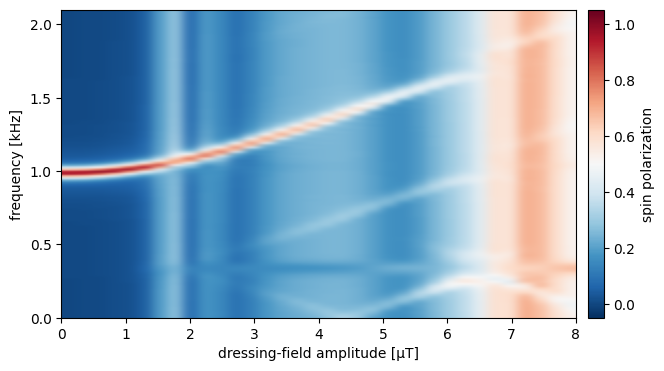

In [6]:
fig, ax = plt.subplots(figsize=(8,4))

# plot the density map
extent=(X.min(), X.max(), 0, F_SF[-1])
cs = ax.imshow(signal, extent=extent, 
               aspect='auto', vmin=-0.05, vmax=1.05, cmap='RdBu_r', interpolation='gaussian')

# plot the colorbar
cb = plt.colorbar(cs, pad=0.02, label='spin polarization')

yticks = np.arange(0, 2000+0.1, 500, dtype=int)
ax.set(xlabel=r'dressing-field amplitude [µT]',
       ylabel='frequency [kHz]',
       xlim=(0,8), ylim=(0, 2100),
       yticks=yticks, yticklabels=yticks/1000
      )

plt.show()

## Simulate

### Single Dressing-Field Amplitude

In [ ]:
# dressing field amplitudes in [µT]
Bd = 0

# spin-flip frequency in [Hz]
F_SF = np.arange(850, 1150+1, 50)
Omega_SF = 2*pi*F_SF

In [ ]:
fProc = partial(sim.dressedResonanceScan, Bd=Bd/1e6)
with Pool(processes=8) as pool:
    job = pool.map_async(fProc, Omega_SF)
    sim.track_job(job, update_interval=1)
pFlip = np.asarray(job.get()).T

### Dressing-Field Amplitude Range

In [ ]:
# dressing field amplitudes in [µT]
BD = np.arange(0, 70+1, 2)

# spin-flip frequency in [Hz]
F_SF = np.arange(15, 2100+1, 15)
Omega_SF = 2*pi*F_SF

In [ ]:
for Bd in BD:

    print(Bd)
    
    fProc = partial(workers.dressedResonanceScan, Bd=Bd/1e6)
    with Pool(processes=8) as pool:
        job = pool.map_async(fProc, Omega_SF)
        track_job(job, update_interval=1)
    pFlip = np.asarray(job.get()).T
    
    np.savez(f'sim/dressedStates_{int(Bd/2):02d}.npz', Bd=Bd/1e6, F_SF=F_SF, Amp=pFlip)